# Phase 5 — Results, discussion and conclusion

This notebook only **reads** the outputs of Phases 1-4 (`results/`, `models/`, `data/processed/`) and assembles the final summary. Nothing here is typed in by hand:
every number comes from files produced by executed code. Run Phases 1-4 first.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score
from eeg_signal_classification import evaluate as ev, train as tr
from eeg_signal_classification.utils import FEATURE_FILE, MODELS_DIR, RESULTS_DIR, load_json, load_structure, set_seed

set_seed(); sns.set_theme(style="whitegrid"); FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
structure = load_structure(); summary = load_json(RESULTS_DIR / "dataset_summary.json")
metrics = pd.read_csv(RESULTS_DIR / "model_metrics.csv", index_col=0)
pred = pd.read_csv(RESULTS_DIR / "predictions.csv")
lines = []   # collected for results/results_summary.md

## 1. Dataset summary and limitations

In [2]:
audit = pd.read_csv(RESULTS_DIR / "metadata_audit.csv"); pd.set_option("display.max_colwidth", 110)
display(audit)
print("layout:", structure["layout"], "| sampling rate:", structure["fs_status"], "| labels:", structure["label_status"])
lines += [f"- Rows x columns: {summary['n_rows']} x {summary['n_columns']}; class counts {summary['label_counts']}",
          f"- Row layout verdict: **{structure['layout']}** ({structure['structure_note']})",
          f"- Sampling rate: {structure['fs_status']}", f"- Label meaning: {structure['label_status']}",
          "- No patient/recording identifiers: patient-independent evaluation is not possible."]

,item,status,evidence / consequence
0,"File size, rows, columns",verified,"11233 x 36865, 2.647 GB"
1,"All signal columns numeric, no NaN/inf",verified,"NaN=0, inf=0"
2,Duplicate rows,verified,877
3,Column-wise standard scaling,consistent with creator's claim,"{'column_means_near_0': True, 'column_stds_near_1': True, 'consistent_with_column_wise_standard_scaling': ..."
4,Meaning of target labels,inferred,"seizure = 1, non-seizure = 0"
5,Row structure / segment layout,blocks,18 blocks x 2048 samples (inferred from data)
6,Physical channel arrangement (which electrode),MISSING,"blocks, if any, cannot be mapped to electrodes from this CSV"
7,Sampling frequency,MISSING,not in CSV; source database is 256 Hz but resampling is undocumented
8,Segment duration in seconds,MISSING,depends on the sampling frequency
9,Physical units (microvolts),LOST,standard scaling turned values into dimensionless z-scores


layout: blocks | sampling rate: unknown - analysis in normalised frequency | labels: inferred: observed class counts match the counts reported by the dataset creator


## 2-3. Signal-processing observations and frequency-domain comparison

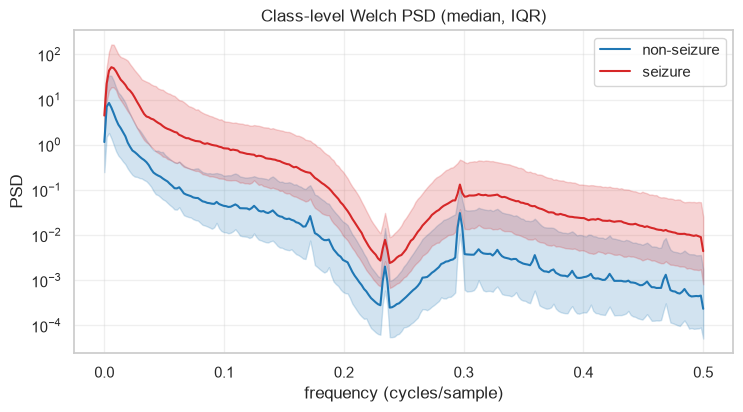

,median seizure,median non-seizure,ratio (seizure / non),Mann-Whitney p
band,,,,
nb1,0.9298,0.9374,0.9920,0.6721
nb2,0.0507,0.0391,1.2949,0.0291
nb3,0.0038,0.0085,0.4529,0.0000
nb4,0.0087,0.0054,1.6153,0.0212
nb5,0.0025,0.0018,1.3764,0.1044


In [3]:
psd_file = RESULTS_DIR / "class_mean_psd.npz"
if psd_file.exists():
    d = np.load(psd_file); unit = str(d["unit"])
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    for c, name, col in ((0, "non-seizure", "tab:blue"), (1, "seizure", "tab:red")):
        ax.semilogy(d["freqs"], d[f"median_{c}"], color=col, label=name); ax.fill_between(d["freqs"], d[f"q25_{c}"], d[f"q75_{c}"], color=col, alpha=0.2)
    ax.set(title="Class-level Welch PSD (median, IQR)", xlabel=f"frequency ({unit})", ylabel="PSD"); ax.legend(); ax.grid(alpha=0.3)
    fig.savefig(FIG / "05_class_psd.png", dpi=150, bbox_inches="tight"); plt.show()
    band_file = RESULTS_DIR / "band_power_comparison.csv"
    if band_file.exists():
        bands = pd.read_csv(band_file, index_col=0); display(bands.round(4))
        lines.append("- Relative band power, seizure / non-seizure median ratio: " + ", ".join(f"{b} x{r:.2f}" for b, r in bands["ratio (seizure / non)"].items()))
else:
    print("No class PSD file: Phase 2 skipped the waveform analysis because the row structure was not verified.")
    lines.append("- Spectral analysis was skipped: row structure not verified.")

## 4. Feature analysis

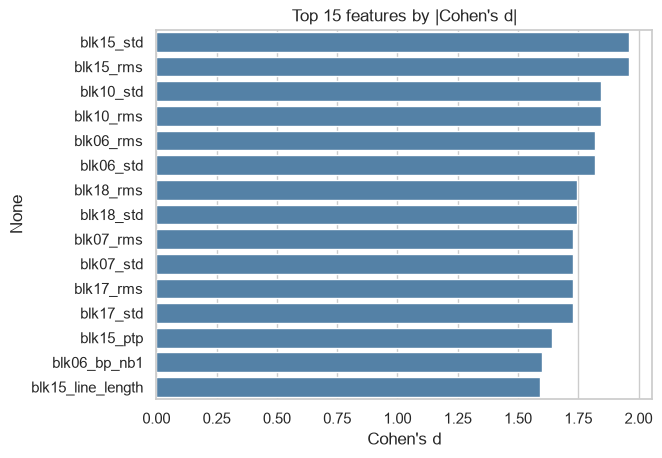

In [4]:
effect = pd.read_csv(RESULTS_DIR / "feature_effect_sizes.csv", index_col=0)
top = effect.head(15)
ax = sns.barplot(x=top["cohens_d"], y=top.index, color="steelblue"); ax.set(title="Top 15 features by |Cohen's d|", xlabel="Cohen's d")
plt.savefig(FIG / "05_effect_sizes.png", dpi=150, bbox_inches="tight"); plt.show()
lines.append("- Most discriminative single features (|Cohen's d|): " + ", ".join(f"{n} ({v:+.2f})" for n, v in top["cohens_d"].head(5).items()))

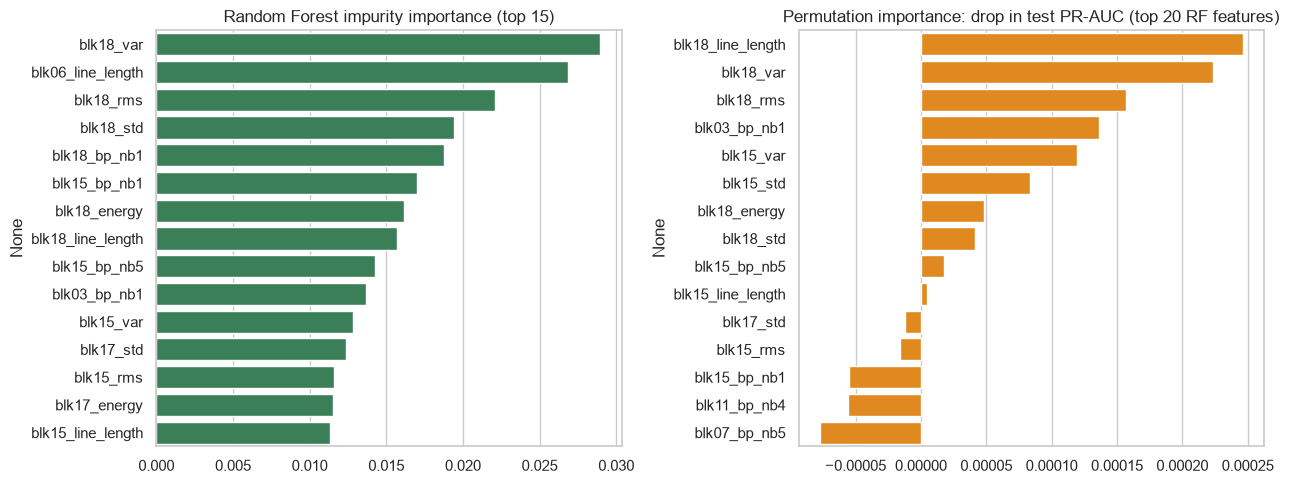

In [5]:
# Random Forest importance (built into the model) and permutation importance on the TEST set for the top features
table = tr.load_feature_table(FEATURE_FILE)
X, y, row_index = tr.prepare_xy(table, structure["seizure_label"])
split = pd.read_csv(RESULTS_DIR / "split_indices.csv"); test_mask = (split["split"] == "test").to_numpy()
X_test, y_test = X[test_mask], y[test_mask]
rf = joblib.load(MODELS_DIR / "random_forest.joblib")
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
candidates = importance.index[:20]
rng, base = np.random.default_rng(42), average_precision_score(y_test, rf.predict_proba(X_test)[:, 1])
perm = {}
for feat in candidates:
    drops = []
    for _ in range(5):
        Xp = X_test.copy(); Xp[feat] = rng.permutation(Xp[feat].to_numpy())
        drops.append(base - average_precision_score(y_test, rf.predict_proba(Xp)[:, 1]))
    perm[feat] = np.mean(drops)
perm = pd.Series(perm).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index, ax=axes[0], color="seagreen"); axes[0].set(title="Random Forest impurity importance (top 15)")
sns.barplot(x=perm.head(15).values, y=perm.head(15).index, ax=axes[1], color="darkorange"); axes[1].set(title="Permutation importance: drop in test PR-AUC (top 20 RF features)")
fig.tight_layout(); fig.savefig(FIG / "05_feature_importance.png", dpi=150); plt.show()
lines.append("- Random Forest top features: " + ", ".join(importance.index[:5]))

## 5-6. Model performance and confusion matrices (test set, from saved predictions)

,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc
Logistic Regression,0.9733,0.9743,0.8408,0.9756,0.9730,0.9032,0.9961,0.9746
SVM (RBF),0.9853,0.9797,0.9178,0.9721,0.9872,0.9442,0.9989,0.9931
Random Forest,0.9924,0.9748,0.9891,0.9512,0.9985,0.9698,0.9993,0.9963


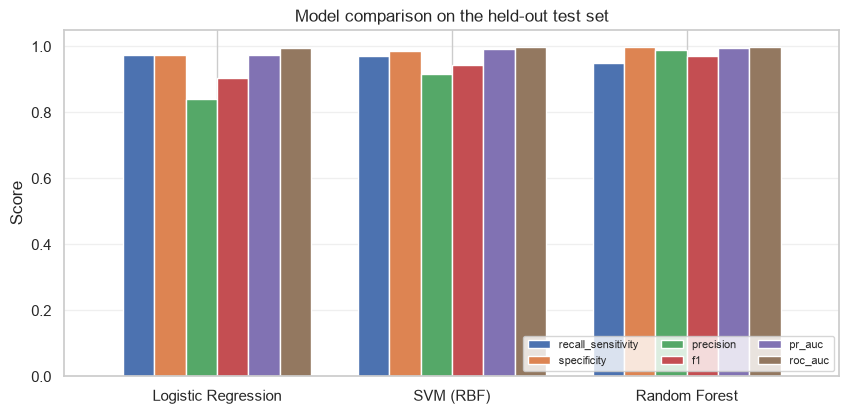

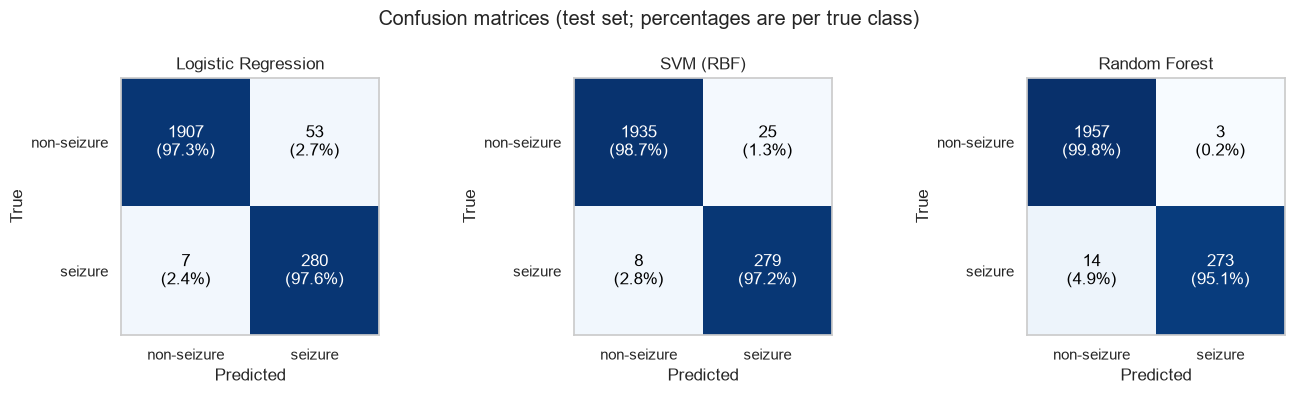

In [6]:
results = {}
for name in metrics.index:
    results[name] = {"y_true": pred["y_true"].to_numpy(), "y_pred": pred[f"{name} | pred"].to_numpy(), "scores": pred[f"{name} | score"].to_numpy()}
shown = ["accuracy", "balanced_accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc", "pr_auc"]
display(metrics[shown].round(4))
ev.plot_model_comparison(metrics).savefig(FIG / "05_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()
ev.plot_confusion_matrices(results).savefig(FIG / "05_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()
best = metrics["pr_auc"].idxmax()
lines += ["", "| model | sensitivity | specificity | precision | F1 | PR-AUC | ROC-AUC |", "|---|---|---|---|---|---|---|"]
lines += [f"| {n} | {r.recall_sensitivity:.3f} | {r.specificity:.3f} | {r.precision:.3f} | {r.f1:.3f} | {r.pr_auc:.3f} | {r.roc_auc:.3f} |" for n, r in metrics.iterrows()]
lines.append(f"\nBest model by PR-AUC: **{best}** (test set, random stratified segment-level split).")

In [7]:
ordered_file = RESULTS_DIR / "ordered_split_check.csv"
if ordered_file.exists():
    ordered = pd.read_csv(ordered_file, index_col=0)
    check = pd.DataFrame({"PR-AUC random split": metrics["pr_auc"], "PR-AUC ordered split": ordered["pr_auc"]}); display(check.round(4))
    lines.append("- Ordered-split sensitivity check (PR-AUC random -> ordered): " + ", ".join(f"{n} {r['PR-AUC random split']:.3f} -> {r['PR-AUC ordered split']:.3f}" for n, r in check.iterrows()))
else:
    print("No ordered-split check was produced (too few seizure rows in one part).")

,PR-AUC random split,PR-AUC ordered split
Logistic Regression,0.9746,0.9640
SVM (RBF),0.9931,0.9932
Random Forest,0.9963,1.0000


## 7. Discussion: limitations, imbalance, leakage, generalisation

* **Dataset provenance.** The CSV is a derivative of CHB-MIT prepared by a third party. Channel layout, sampling rate, segment length and the meaning of the label were
  not documented on the Kaggle page; Phase 1 recovered what the data allow and flagged the rest. Any Hz-labelled result is conditional on the sampling-rate assumption (if one was made).
* **No patient or recording identifiers.** The train/test split is a random stratified split of segments. Neighbouring segments from the same recording can end up on both sides,
  which inflates the scores. **The results do not demonstrate generalisation to unseen patients**, and the ordered-split check above is only a partial warning, not a substitute.
* **Class imbalance (~13 % seizure).** Accuracy is dominated by the majority class. We used class weights and report sensitivity, specificity, F1 and PR-AUC.
  No resampling (e.g. SMOTE) was used; it can create unrealistic synthetic EEG features and would have to be fitted inside cross-validation folds.
* **Standard scaling by the dataset creator.** Column-wise scaling removed physical units and may have been fitted on all rows including what we call the test set (we cannot know),
  a small additional leakage source we cannot control.
* **Statistical tests** in Phase 2 treat rows as independent, which is optimistic for the same reason.
* **Not a medical device.** Nothing here is clinically validated; seizure detection in practice also needs event-level metrics (false alarms per hour, detection latency) that a segment-level CSV cannot provide.

## 8. Conclusions and future work

In [8]:
m = metrics.loc[best]
conclusion = (f"On a random stratified segment-level test split, the best model by PR-AUC was {best} "
              f"(sensitivity {m.recall_sensitivity:.2f}, specificity {m.specificity:.2f}, PR-AUC {m.pr_auc:.2f}, ROC-AUC {m.roc_auc:.2f}). "
              "These numbers describe performance on segments similar to the training data, not performance on new patients.")
print(conclusion); lines.insert(0, conclusion + "\n")
(RESULTS_DIR / "results_summary.md").write_text("\n".join(lines), encoding="utf-8")
print("written:", RESULTS_DIR / "results_summary.md")

On a random stratified segment-level test split, the best model by PR-AUC was Random Forest (sensitivity 0.95, specificity 1.00, PR-AUC 1.00, ROC-AUC 1.00). These numbers describe performance on segments similar to the training data, not performance on new patients.
written: C:\eeg\results\results_summary.md


**Future improvements (in order of value):** (1) use the original CHB-MIT EDF files and the official seizure annotations so that channels, sampling rate and **patient-wise / leave-one-patient-out**
evaluation are possible; (2) event-based metrics (false alarms/hour, latency); (3) probability calibration and operating-point selection on a validation set; (4) a 1D CNN on raw segments, once the data structure is verified;
(5) explainability and a GenAI report assistant as optional extensions after the core results are solid.